# Modularity on the Karate Club Graph

Community Detection using Spectral Modularity

Objective:
The objective of this assignment is to implement a recursive spectral modularity algorithm to identify communities in the Karate Club network. We will visualize the detected communities and analyse how different network centrality measures evolve after each split.

Dataset: Zachary's Karate Club Graph

In [207]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 7)

print("All libraries imported successfully!")

All libraries imported successfully!


In [208]:

G = nx.karate_club_graph()

pos = nx.spring_layout(G, seed=42)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is the graph directed?", nx.is_directed(G))

Number of nodes: 34
Number of edges: 78
Is the graph directed? False


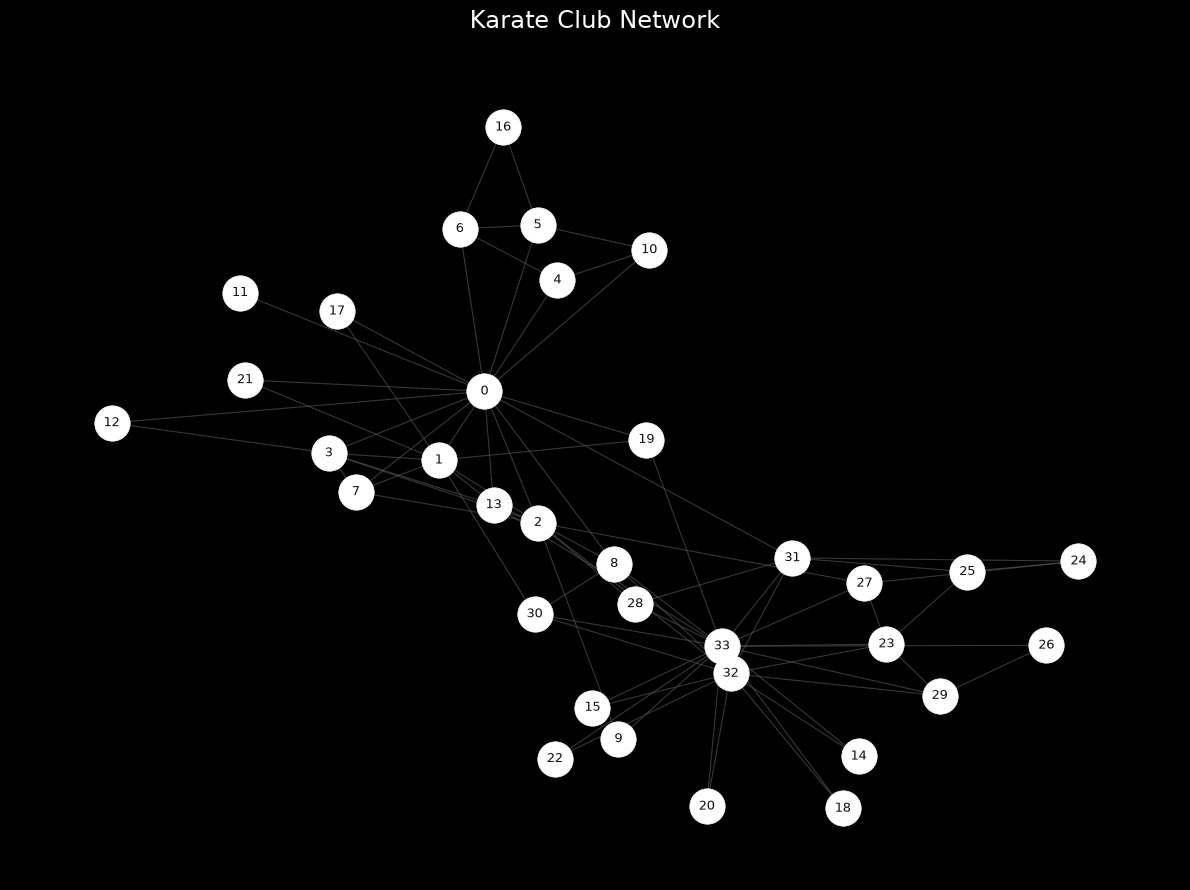

In [209]:

fig, ax = plt.subplots(figsize=(12, 9))

fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

nx.draw_networkx_edges(
    G,
    pos,
    ax=ax,
    edge_color="#555555",
    width=0.8,
    alpha=0.65
)

nx.draw_networkx_nodes(
    G,
    pos,
    ax=ax,
    node_color="#FFFFFF",
    node_size=650,
    edgecolors="#FFFFFF",
    linewidths=0.5
)

nx.draw_networkx_labels(
    G,
    pos,
    ax=ax,
    font_color="#111111",
    font_size=9,
    font_family="Sans"
)

ax.set_title(
    "Karate Club Network",
    color="#FFFFFF",
    fontsize=17,
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()


Construction of the Modularity Matrix

The adjacency matrix represents the connections between nodes in the Karate Club graph. An entry is 1 if two nodes are connected and 0 otherwise.

In [210]:

A = nx.to_numpy_array(G, weight=None, dtype=float)

k = np.sum(A, axis=1)

print("Adjacency matrix shape:", A.shape)
print("Total degree:", int(np.sum(k)))
print("Total edges:", G.number_of_edges())

Adjacency matrix shape: (34, 34)
Total degree: 156
Total edges: 78


In [211]:

k = np.sum(A, axis=1)

print("Degree of each node:\n")

for node, degree in enumerate(k):
    print(f"Node {node}: {int(degree)}")

Degree of each node:

Node 0: 16
Node 1: 9
Node 2: 10
Node 3: 6
Node 4: 3
Node 5: 4
Node 6: 4
Node 7: 4
Node 8: 5
Node 9: 2
Node 10: 3
Node 11: 1
Node 12: 2
Node 13: 5
Node 14: 2
Node 15: 2
Node 16: 2
Node 17: 2
Node 18: 2
Node 19: 3
Node 20: 2
Node 21: 2
Node 22: 2
Node 23: 5
Node 24: 3
Node 25: 3
Node 26: 2
Node 27: 4
Node 28: 3
Node 29: 4
Node 30: 4
Node 31: 6
Node 32: 12
Node 33: 17


In [212]:

m = G.number_of_edges()

print("Total number of edges:", m)
print("Total degree:", int(np.sum(k)))

Total number of edges: 78
Total degree: 156


In [213]:

B = A - np.outer(k, k) / (2 * m)

print("Modularity matrix shape:", B.shape)

print("Is B symmetric?", np.allclose(B, B.T))

print("Sum of all row sums:", np.sum(B))

Modularity matrix shape: (34, 34)
Is B symmetric? True
Sum of all row sums: -3.774758283725532e-15


Spectral Community Detection

The eigenvalues and eigenvectors of the modularity matrix are used to identify potential community divisions.

The eigenvector corresponding to the largest eigenvalue is called the leading eigenvector. Its signs determine the two initial communities.

In [214]:

eigenvalues, eigenvectors = np.linalg.eigh(B)

largest_index = np.argmax(eigenvalues)

largest_eigenvalue = eigenvalues[largest_index]

leading_eigenvector = eigenvectors[:, largest_index]

print("Largest eigenvalue:", largest_eigenvalue)
print("\nLeading eigenvector:")
print(leading_eigenvector)

Largest eigenvalue: 4.977080225729888

Leading eigenvector:
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


In [215]:

communities = {}

for node in G.nodes():
    if leading_eigenvector[node] > 0:
        communities[node] = 1
    else:
        communities[node] = 2


community_1 = [node for node in G.nodes() if communities[node] == 1]
community_2 = [node for node in G.nodes() if communities[node] == 2]

print("Community 1:", community_1)
print("\nCommunity 2:", community_2)

print("\nNumber of nodes in Community 1:", len(community_1))
print("Number of nodes in Community 2:", len(community_2))

Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]

Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Number of nodes in Community 1: 16
Number of nodes in Community 2: 18


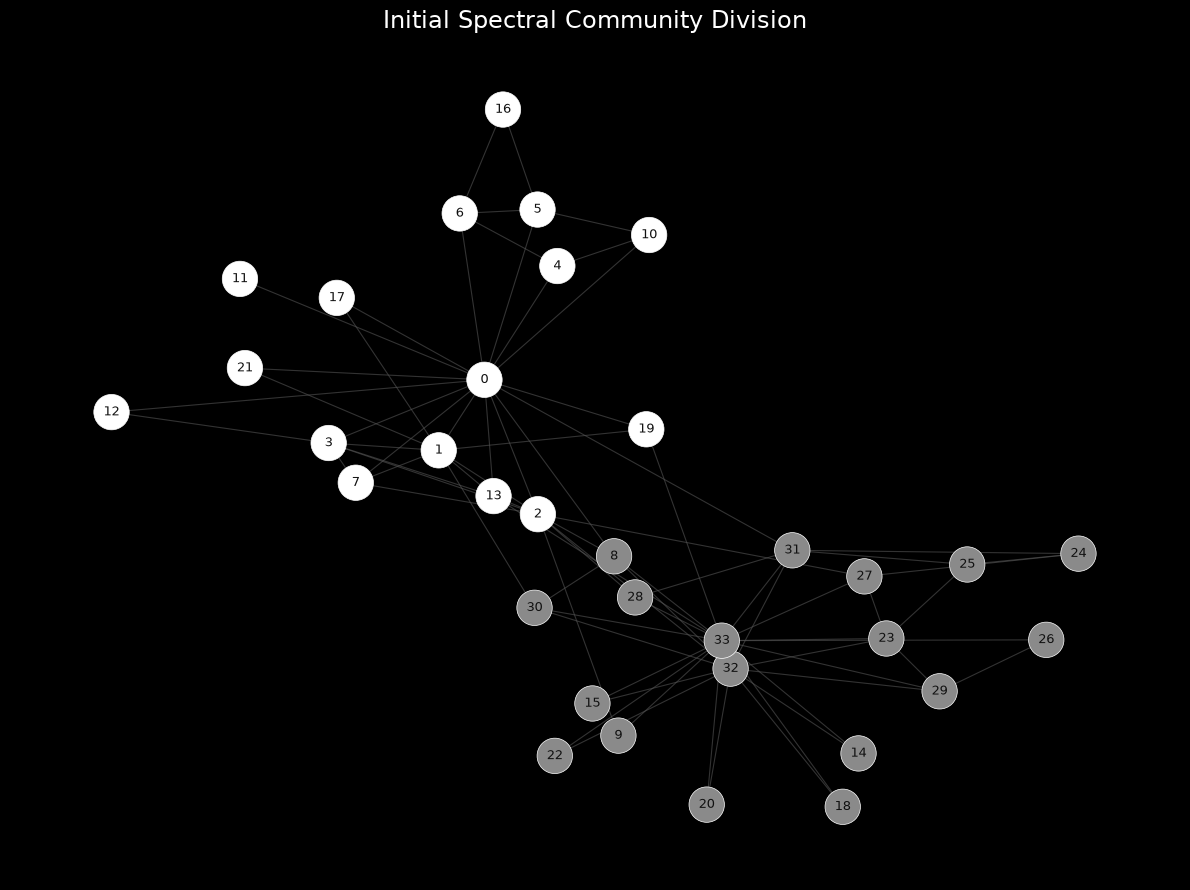

In [216]:

node_colors = [
    "#FFFFFF" if communities[node] == 1 else "#8A8A8A"
    for node in G.nodes()
]

fig, ax = plt.subplots(figsize=(12, 9))

fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

nx.draw_networkx_edges(
    G, pos,
    ax=ax,
    edge_color="#555555",
    alpha=0.6,
    width=0.8
)

nx.draw_networkx_nodes(
    G, pos,
    ax=ax,
    node_color=node_colors,
    node_size=650,
    edgecolors="#FFFFFF",
    linewidths=0.5
)

nx.draw_networkx_labels(
    G, pos,
    ax=ax,
    font_color="#111111",
    font_size=9,
)

ax.set_title(
    "Initial Spectral Community Division",
    color="white",
    fontsize=17,
)

ax.axis("off")
plt.tight_layout()
plt.show()

Recursive Spectral Modularity Partitioning

The initial community is recursively divided using the restricted modularity matrix.

For each community, the largest eigenvalue is calculated. If it is positive, the community is divided according to the signs of its leading eigenvector. The process continues until no further positive-eigenvalue split is possible.

In [217]:

# Recursive spectral community detection

# Start with one community containing all nodes
final_communities = [list(G.nodes())]

# Store the partition after every successful split
partition_history = [[list(c) for c in final_communities]]


def recursive_split(community):

    # A single node cannot be split
    if len(community) < 2:
        return

    # Sort nodes to maintain consistent matrix indexing
    nodes = sorted(community)

    # Extract the restricted modularity matrix
    B_C = B[np.ix_(nodes, nodes)]

    # Calculate eigenvalues and eigenvectors
    eigenvalues_C, eigenvectors_C = np.linalg.eigh(B_C)

    # Find the leading eigenvalue and eigenvector
    index = np.argmax(eigenvalues_C)

    leading_value = eigenvalues_C[index]
    leading_vector = eigenvectors_C[:, index]

    print("Community:", nodes)
    print("Largest eigenvalue:", round(leading_value, 4))

    # Stop if the largest eigenvalue is nonpositive
    if leading_value <= 1e-10:
        print("No further split possible.\n")
        return

    # Divide nodes according to eigenvector signs
    group_positive = [
        nodes[i] for i in range(len(nodes))
        if leading_vector[i] > 0
    ]

    group_negative = [
        nodes[i] for i in range(len(nodes))
        if leading_vector[i] <= 0
    ]

    # Prevent empty communities
    if len(group_positive) == 0 or len(group_negative) == 0:
        print("No valid bipartition found.\n")
        return

    print("Split into:", len(group_positive),
          "and", len(group_negative), "nodes\n")

    # Replace the original community with its two subcommunities
    community_index = next(
        i for i, c in enumerate(final_communities)
        if set(c) == set(nodes)
    )

    final_communities.pop(community_index)

    final_communities.extend([
        group_positive,
        group_negative
    ])

    # Save the current partition
    partition_history.append(
        [list(c) for c in final_communities]
    )

    # Recursively split both resulting communities
    recursive_split(group_positive)
    recursive_split(group_negative)


# Run the recursive algorithm
recursive_split(list(G.nodes()))

print("\nFINAL COMMUNITIES")

for i, community in enumerate(final_communities):
    print(f"Community {i+1}: {sorted(community)}")

print("\nTotal communities detected:", len(final_communities))


Community: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 4.9771
Split into: 16 and 18 nodes

Community: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Largest eigenvalue: 2.9441
Split into: 6 and 10 nodes

Community: [4, 5, 6, 10, 11, 16]
Largest eigenvalue: 2.148
Split into: 1 and 5 nodes

Community: [4, 5, 6, 10, 16]
Largest eigenvalue: 2.147
No valid bipartition found.

Community: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Largest eigenvalue: 2.5712
No valid bipartition found.

Community: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 2.5041
Split into: 5 and 13 nodes

Community: [24, 25, 27, 28, 31]
Largest eigenvalue: 1.8759
No valid bipartition found.

Community: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Largest eigenvalue: 2.3563
No valid bipartition found.


FINAL COMMUNITIES
Community 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]

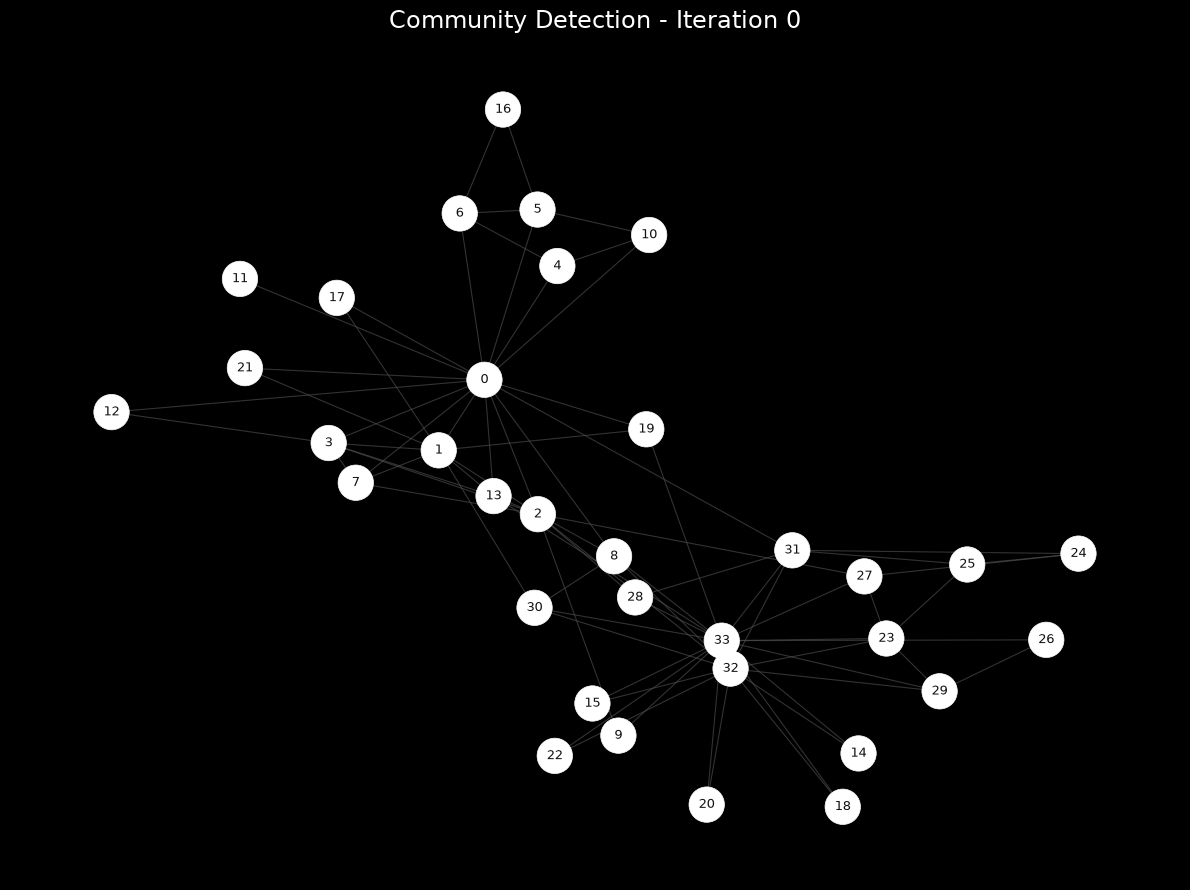

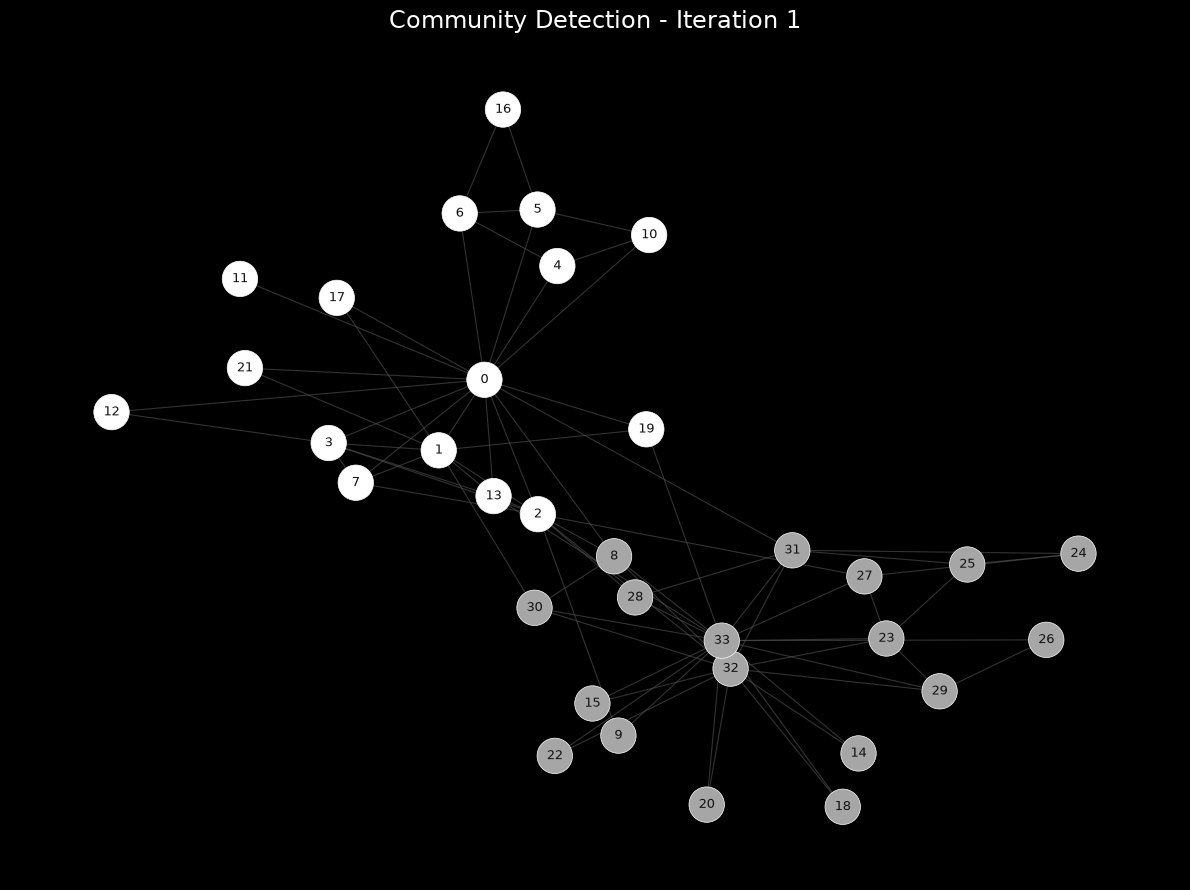

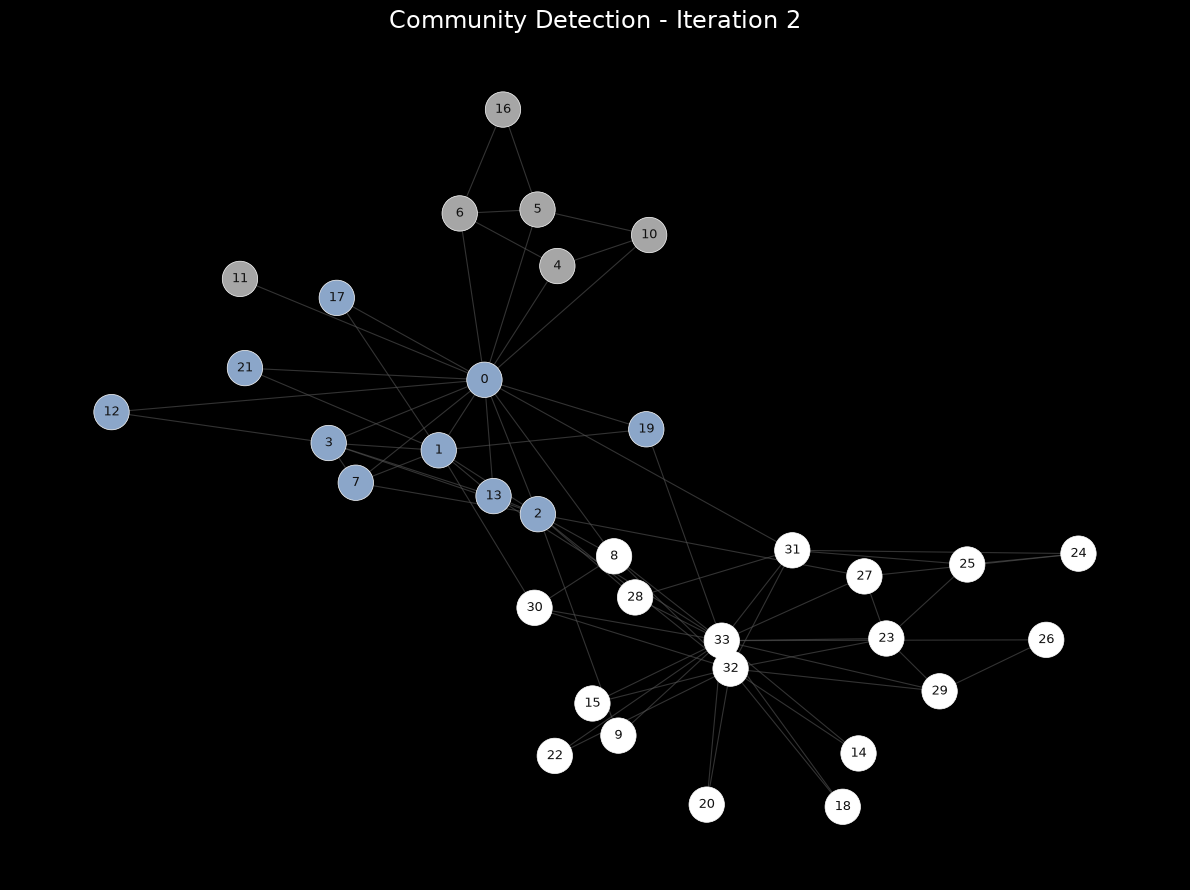

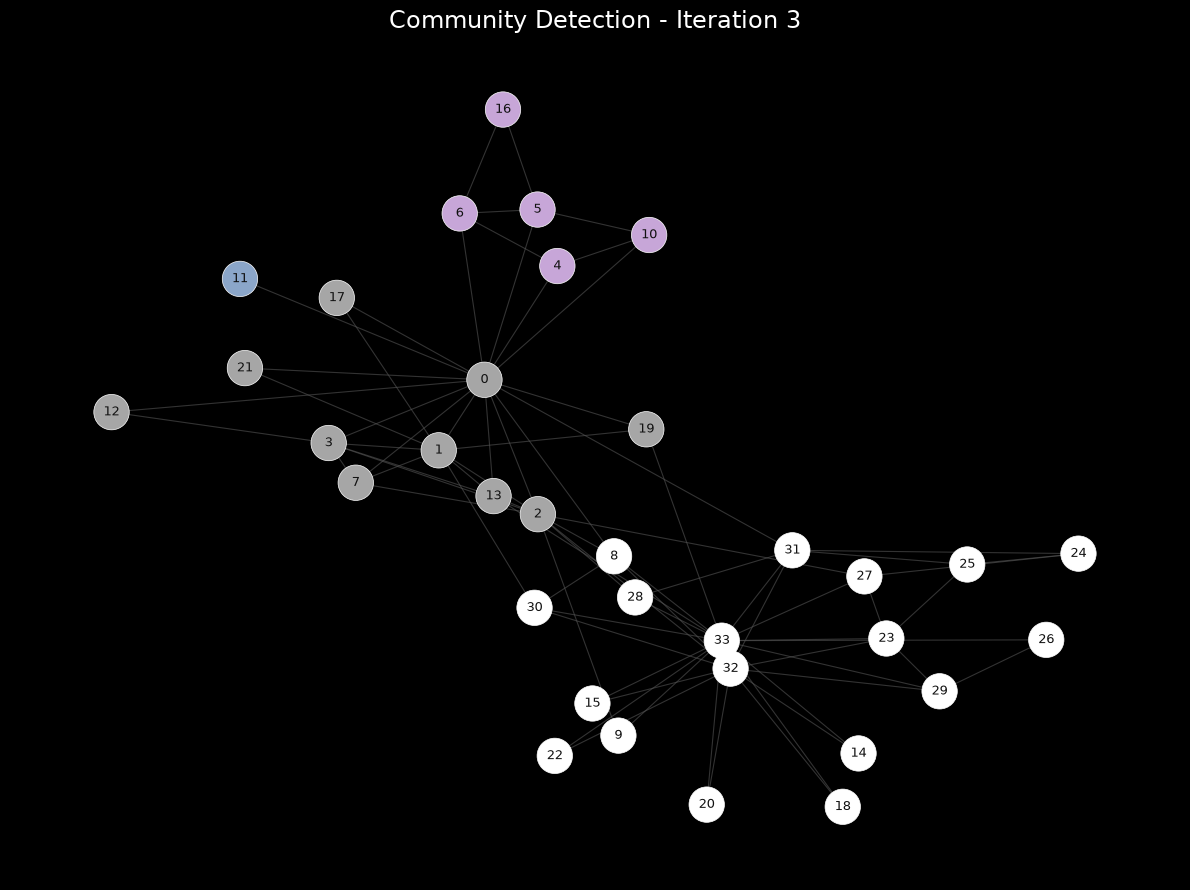

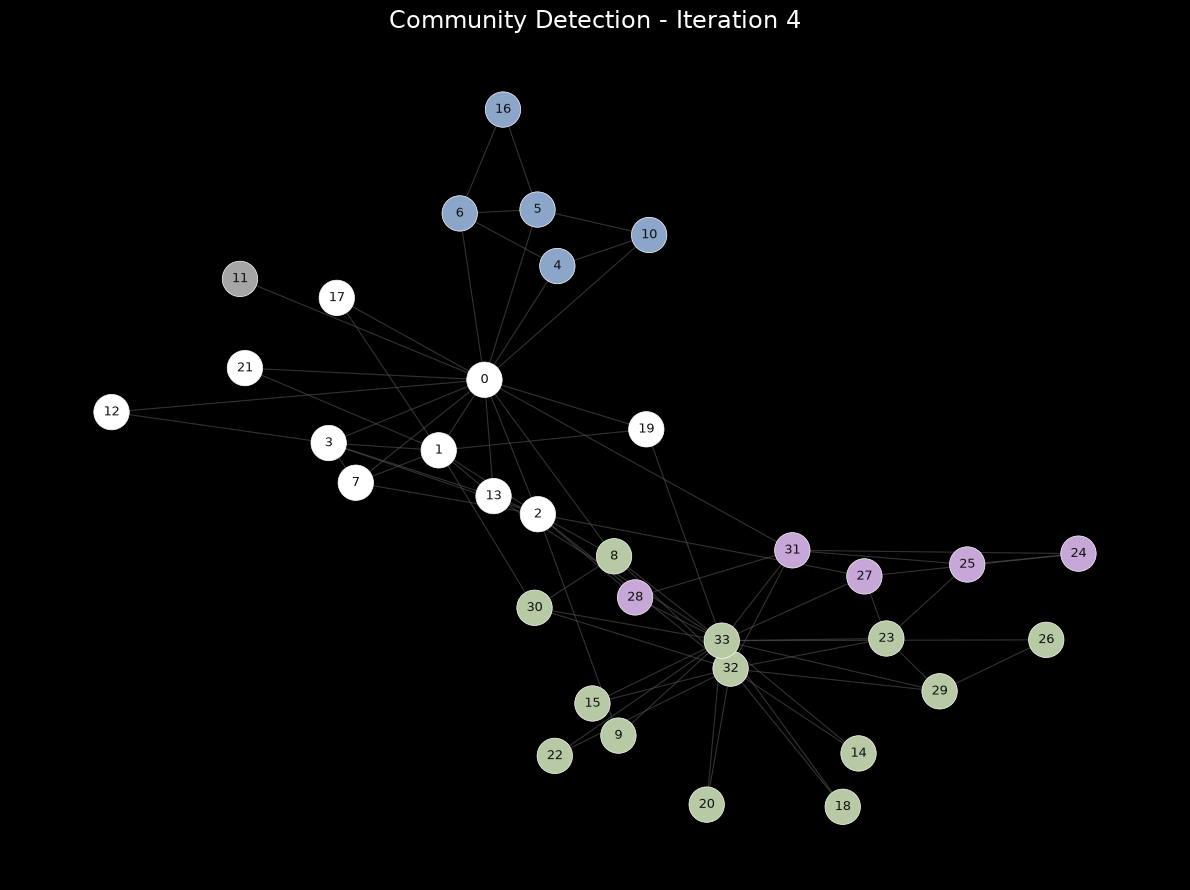

In [218]:


def plot_partition(partition, iteration):

    colors = [
        "#FFFFFF",
        "#A6A6A6",
        "#8BA6C9",
        "#C7A6D8",
        "#B8C9A5",
        "#D9B58C",
        "#85B9B2",
        "#C98F9B"
    ]

    node_colors = {}

    for i, community in enumerate(partition):
        for node in community:
            node_colors[node] = colors[i % len(colors)]

    fig, ax = plt.subplots(figsize=(12, 9))

    fig.patch.set_facecolor("#000000")
    ax.set_facecolor("#000000")

    nx.draw_networkx_edges(
        G, pos,
        ax=ax,
        edge_color="#555555",
        alpha=0.6,
        width=0.8
    )

    nx.draw_networkx_nodes(
        G, pos,
        ax=ax,
        node_color=[node_colors[node] for node in G.nodes()],
        node_size=650,
        edgecolors="#FFFFFF",
        linewidths=0.5
    )

    nx.draw_networkx_labels(
        G, pos,
        ax=ax,
        font_color="#111111",
        font_size=9,
        font_weight="light"
    )

    ax.set_title(
        f"Community Detection - Iteration {iteration}",
        color="white",
        fontsize=17,
        fontweight="light"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()


for i, partition in enumerate(partition_history):
    plot_partition(partition, i)


Limitation of the Initial Recursive Splitting Method

The initial implementation follows the restricted modularity matrix approach described in the assignment. For each community, the corresponding submatrix of the global modularity matrix is extracted, and its leading eigenvector is used to determine the community division.

However, during implementation, a limitation was observed. In certain cases, the restricted modularity matrix produced a positive leading eigenvalue, but all entries of its leading eigenvector had the same sign.

Consequently, thresholding the eigenvector at zero resulted in an empty group, making a valid bipartition impossible.

This occurs because the restricted modularity matrix does not necessarily have zero row sums. Therefore, its leading eigenvector is not guaranteed to contain both positive and negative entries.

Although the initial implementation works for some communities, this limitation prevents it from reliably completing the recursive partitioning process.

To address this issue, a diagonal correction based on the Newman recursive modularity method is introduced in the following section.

Corrected Recursive Spectral Modularity Method

To overcome the limitation identified above, the restricted modularity matrix is modified using a diagonal correction.

The corrected modularity matrix for a community \(C\) is defined as:

\[
B^{(C)}=B_C-\operatorname{diag}(B_C\mathbf{1})
\]

where:

- \(B_C\) is the restricted modularity matrix.
- \(\mathbf{1}\) is the all-ones vector.
- \(\operatorname{diag}(B_C\mathbf{1})\) is a diagonal matrix containing the row sums of \(B_C\).

This correction ensures that the rows of the modified matrix sum to zero.

The leading eigenvalue and eigenvector are then calculated. If the leading eigenvalue is positive, the community is divided according to the signs of the leading eigenvector.

The process is repeated recursively until no further positive-eigenvalue split is possible.

In [219]:

final_communities = [list(G.nodes())]

partition_history = [
    [list(c) for c in final_communities]
]


def recursive_split(community):

    nodes = sorted(community)

    if len(nodes) < 2:
        return

    # Extract restricted modularity matrix
    B_C = B[np.ix_(nodes, nodes)]

    # Apply diagonal correction
    row_sums = np.sum(B_C, axis=1)

    B_corrected = B_C - np.diag(row_sums)

    # Calculate eigenvalues and eigenvectors
    eigenvalues_C, eigenvectors_C = np.linalg.eigh(B_corrected)

    # Find leading eigenpair
    index = np.argmax(eigenvalues_C)

    leading_value = eigenvalues_C[index]
    leading_vector = eigenvectors_C[:, index]

    print("Community:", nodes)
    print("Largest eigenvalue:", round(leading_value, 4))

    # Stopping condition
    if leading_value <= 1e-10:
        print("No further split possible.\n")
        return

    # Divide using eigenvector signs
    group_positive = [
        nodes[i] for i in range(len(nodes))
        if leading_vector[i] >= 0
    ]

    group_negative = [
        nodes[i] for i in range(len(nodes))
        if leading_vector[i] < 0
    ]

    # Ensure both communities contain nodes
    if not group_positive or not group_negative:
        print("No valid split found.\n")
        return

    # Calculate actual modularity gain of the proposed split
    s = np.array([
        1 if node in group_positive else -1
        for node in nodes
    ])

    modularity_gain = (s @ B_corrected @ s) / (4 * m)

    print("Modularity gain:", round(modularity_gain, 6))

    # Accept only modularity-improving splits
    if modularity_gain <= 1e-10:
        print("Split rejected: no modularity improvement.\n")
        return

    print(
        "Split into:",
        len(group_positive),
        "and",
        len(group_negative),
        "nodes\n"
    )

    # Update final communities
    community_index = next(
        i for i, c in enumerate(final_communities)
        if set(c) == set(nodes)
    )

    final_communities.pop(community_index)

    final_communities.extend([
        group_positive,
        group_negative
    ])

    # Store partition after each successful split
    partition_history.append(
        [list(c) for c in final_communities]
    )

    # Recursively process both groups
    recursive_split(group_positive)
    recursive_split(group_negative)


# Execute corrected algorithm
recursive_split(list(G.nodes()))

print("\nFINAL COMMUNITIES")

for i, community in enumerate(final_communities):
    print(f"Community {i+1}: {sorted(community)}")

print("\nTotal communities detected:", len(final_communities))


Community: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 4.9771
Modularity gain: 0.371466
Split into: 16 and 18 nodes

Community: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Largest eigenvalue: 1.1785
Modularity gain: 0.001233
Split into: 7 and 9 nodes

Community: [0, 4, 5, 6, 10, 11, 16]
Largest eigenvalue: 0.0
No further split possible.

Community: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Largest eigenvalue: 0.0602
Modularity gain: -0.015779
Split rejected: no modularity improvement.

Community: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 0.8594
Modularity gain: 0.02071
Split into: 6 and 12 nodes

Community: [23, 24, 25, 27, 28, 31]
Largest eigenvalue: 0.0
No further split possible.

Community: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Largest eigenvalue: -0.0
No further split possible.


FINAL COMMUNITIES
Community 1: [0, 4, 5,

Visualization of the Corrected Community Structure

The corrected recursive spectral modularity algorithm produces five communities. The following visualizations illustrate how the network is progressively divided at each successful iteration.

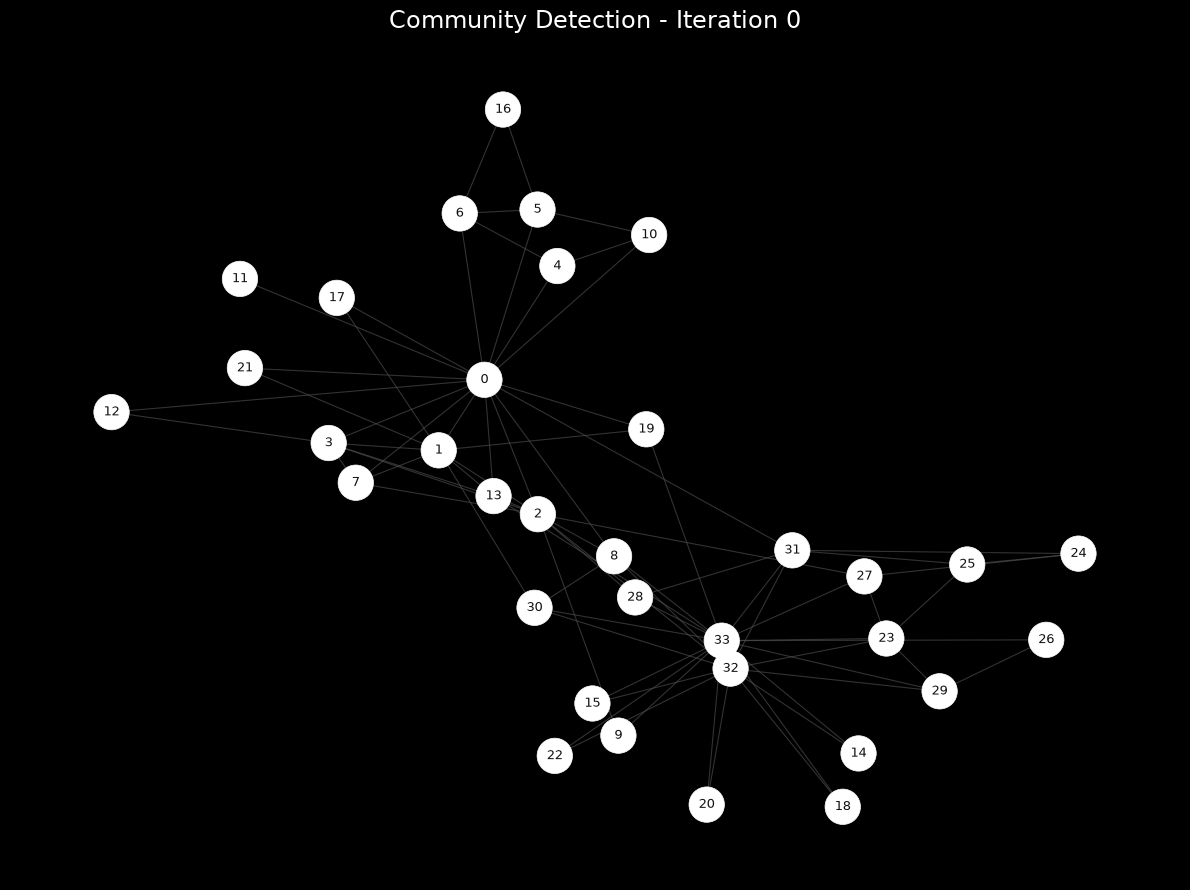

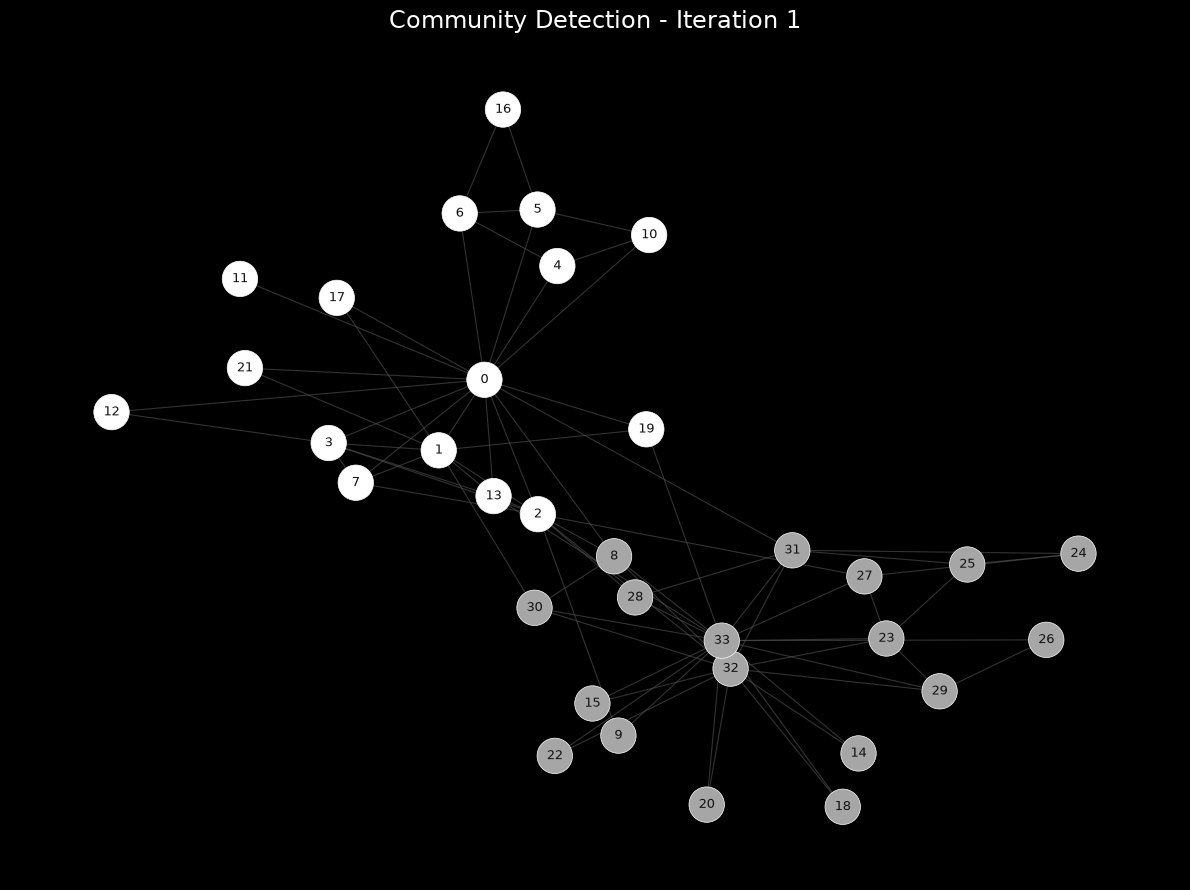

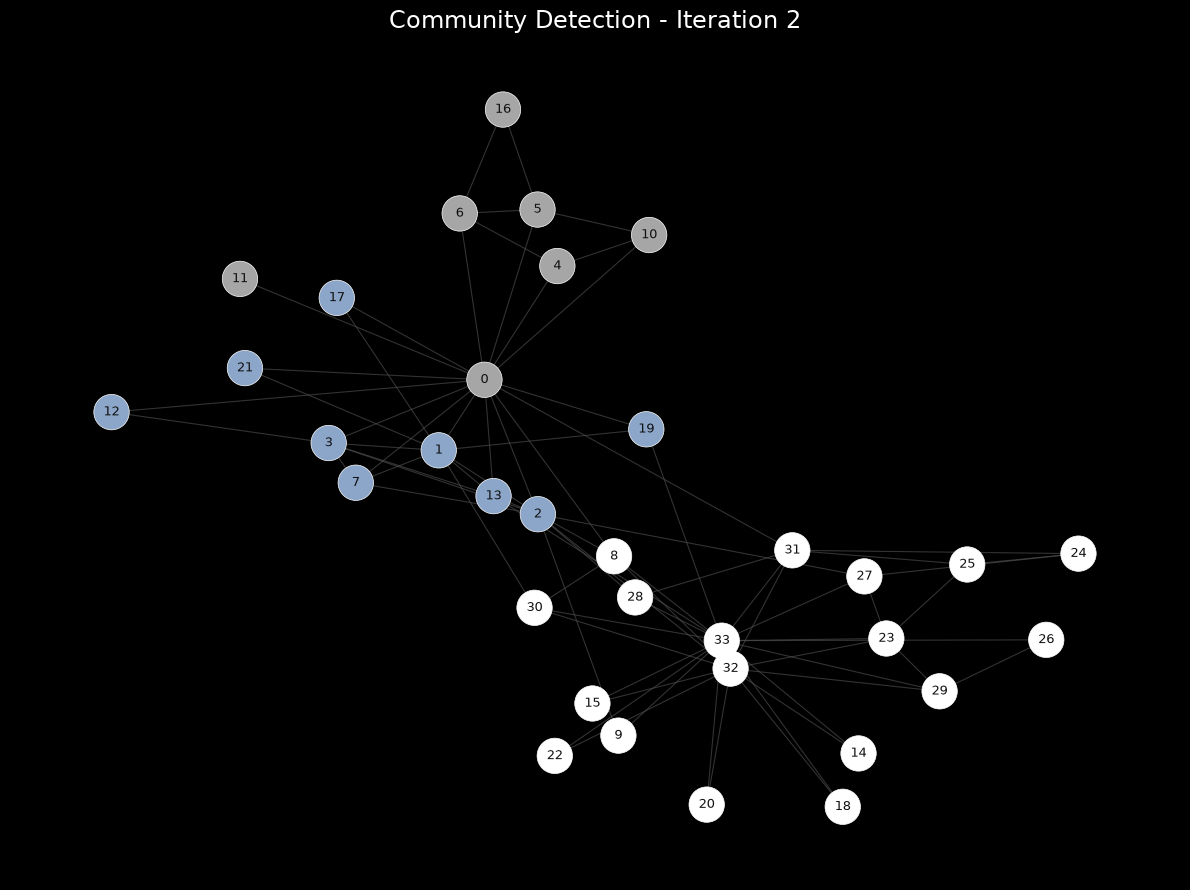

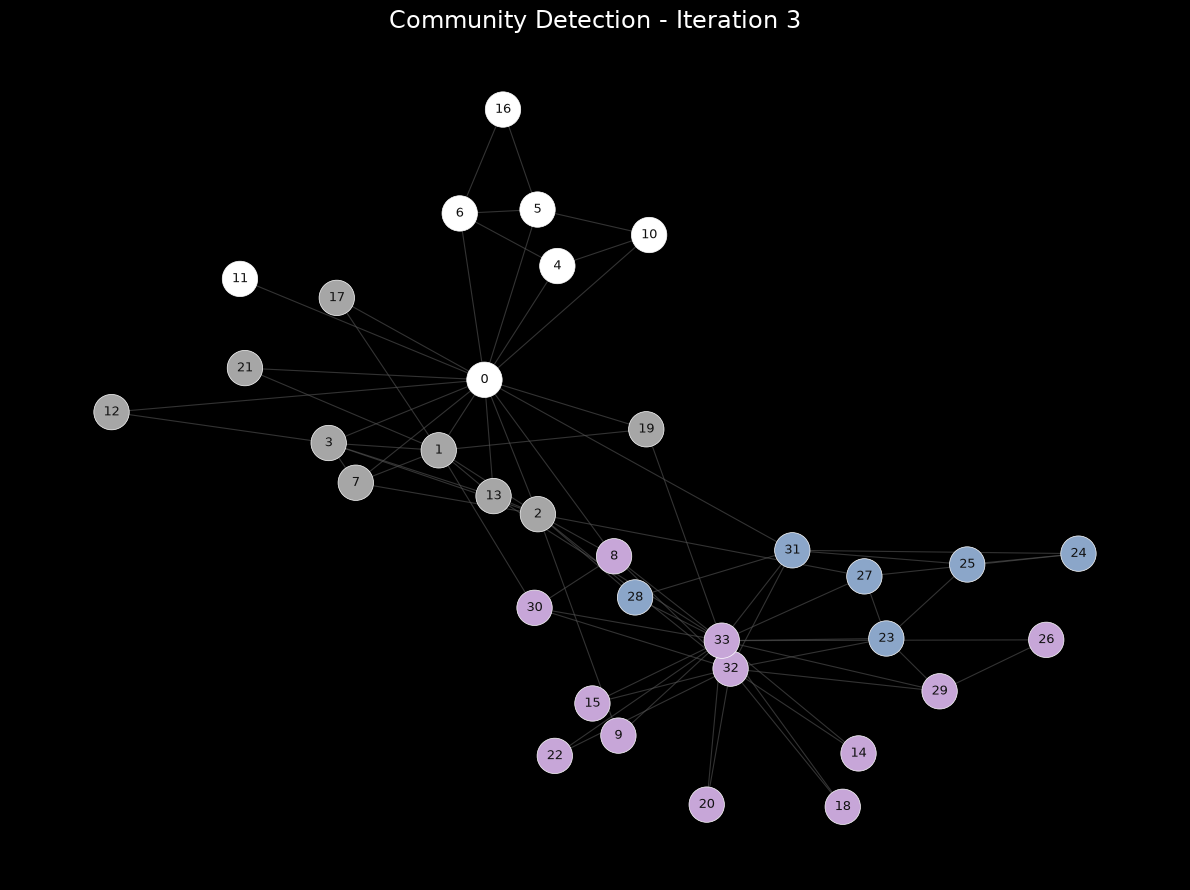


Final community sizes:
Community 1: 7 nodes
Community 2: 9 nodes
Community 3: 6 nodes
Community 4: 12 nodes


In [220]:

for i, partition in enumerate(partition_history):
    plot_partition(partition, i)

print("\nFinal community sizes:")

for i, community in enumerate(final_communities):
    print(f"Community {i+1}: {len(community)} nodes")

Network Metrics and Centrality Analysis

After detecting communities, four network metrics are calculated to analyse the structural importance of individual nodes.

The metrics used are:

1 Degree Centrality: Measures the proportion of nodes directly connected to a given node.
2 Betweenness Centrality: Measures how frequently a node lies on shortest paths between other nodes.
3 Closeness Centrality: Measures how close a node is to all other nodes based on shortest-path distances.
4 Clustering Coefficient: Measures the extent to which a node's neighbours are connected to one another.

These metrics are calculated after each successful community split to examine how the structural importance of nodes changes as the network is divided into smaller communities.

Metric Calculation Method

At each iteration, the graph is divided into its current communities. For every community, an induced subgraph is constructed using the nodes belonging to that community.

The four network metrics are then calculated using NetworkX functions on these induced subgraphs. Each node's metric values are stored according to the iteration number.

This approach allows the analysis to focus on changes in local centrality and cohesion as community boundaries become increasingly refined.

In [221]:

metric_history = {
    "Degree Centrality": [],
    "Betweenness Centrality": [],
    "Closeness Centrality": [],
    "Clustering Coefficient": []
}

for iteration, partition in enumerate(partition_history):

    degree_values = {}
    betweenness_values = {}
    closeness_values = {}
    clustering_values = {}

    # Calculate metrics separately for each community
    for community in partition:

        # Construct the induced subgraph
        H = G.subgraph(community).copy()

        # Handle communities containing only one node
        if len(H) == 1:
            for node in H.nodes():
                degree_values[node] = 0.0
                betweenness_values[node] = 0.0
                closeness_values[node] = 0.0
                clustering_values[node] = 0.0

        else:
            # Calculate all four network metrics
            dc = nx.degree_centrality(H)
            bc = nx.betweenness_centrality(H)
            cc = nx.closeness_centrality(H)
            cl = nx.clustering(H)

            degree_values.update(dc)
            betweenness_values.update(bc)
            closeness_values.update(cc)
            clustering_values.update(cl)

    # Save the results for this iteration
    metric_history["Degree Centrality"].append(degree_values)
    metric_history["Betweenness Centrality"].append(betweenness_values)
    metric_history["Closeness Centrality"].append(closeness_values)
    metric_history["Clustering Coefficient"].append(clustering_values)

    print(
        f"Iteration {iteration}: "
        f"{len(partition)} communities analysed"
    )

print("\nAll four network metrics calculated successfully!")


Iteration 0: 1 communities analysed
Iteration 1: 2 communities analysed
Iteration 2: 3 communities analysed
Iteration 3: 4 communities analysed

All four network metrics calculated successfully!


In [222]:

print("Number of iterations:", len(partition_history))

print("\nNumber of nodes recorded in the final iteration:")

for metric, history in metric_history.items():
    print(metric + ":", len(history[-1]))

print("\nExample: Final metric values for node 0")

for metric, history in metric_history.items():
    print(metric + ":", round(history[-1][0], 4))


Number of iterations: 4

Number of nodes recorded in the final iteration:
Degree Centrality: 34
Betweenness Centrality: 34
Closeness Centrality: 34
Clustering Coefficient: 34

Example: Final metric values for node 0
Degree Centrality: 0.8333
Betweenness Centrality: 0.3778
Closeness Centrality: 0.8571
Clustering Coefficient: 0.4


Evolution of Network Metrics

The evolution of the four network metrics is visualized across successive community partitions.

Each line represents an individual node, while the horizontal axis represents the splitting iteration.

These plots help identify nodes whose structural importance changes significantly as the network is divided into smaller communities.

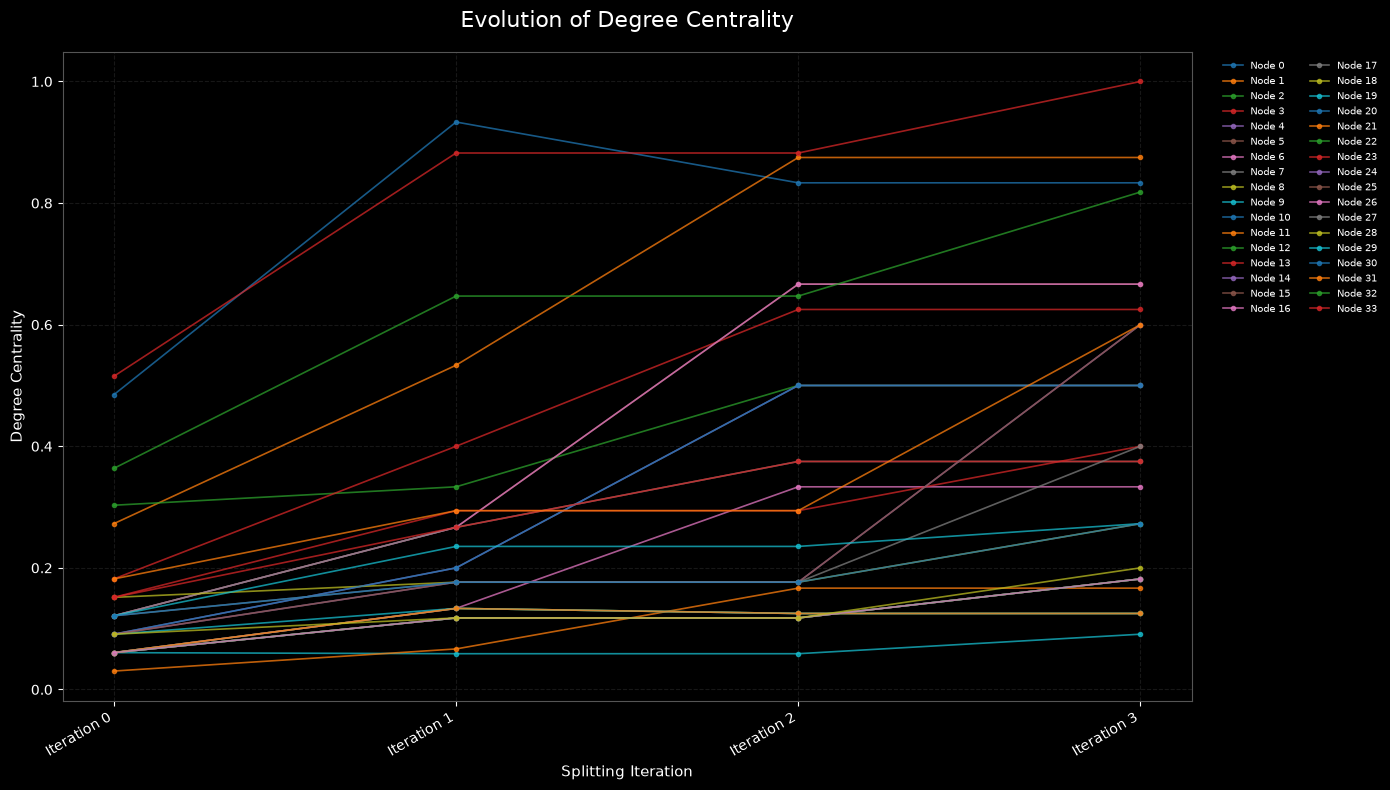

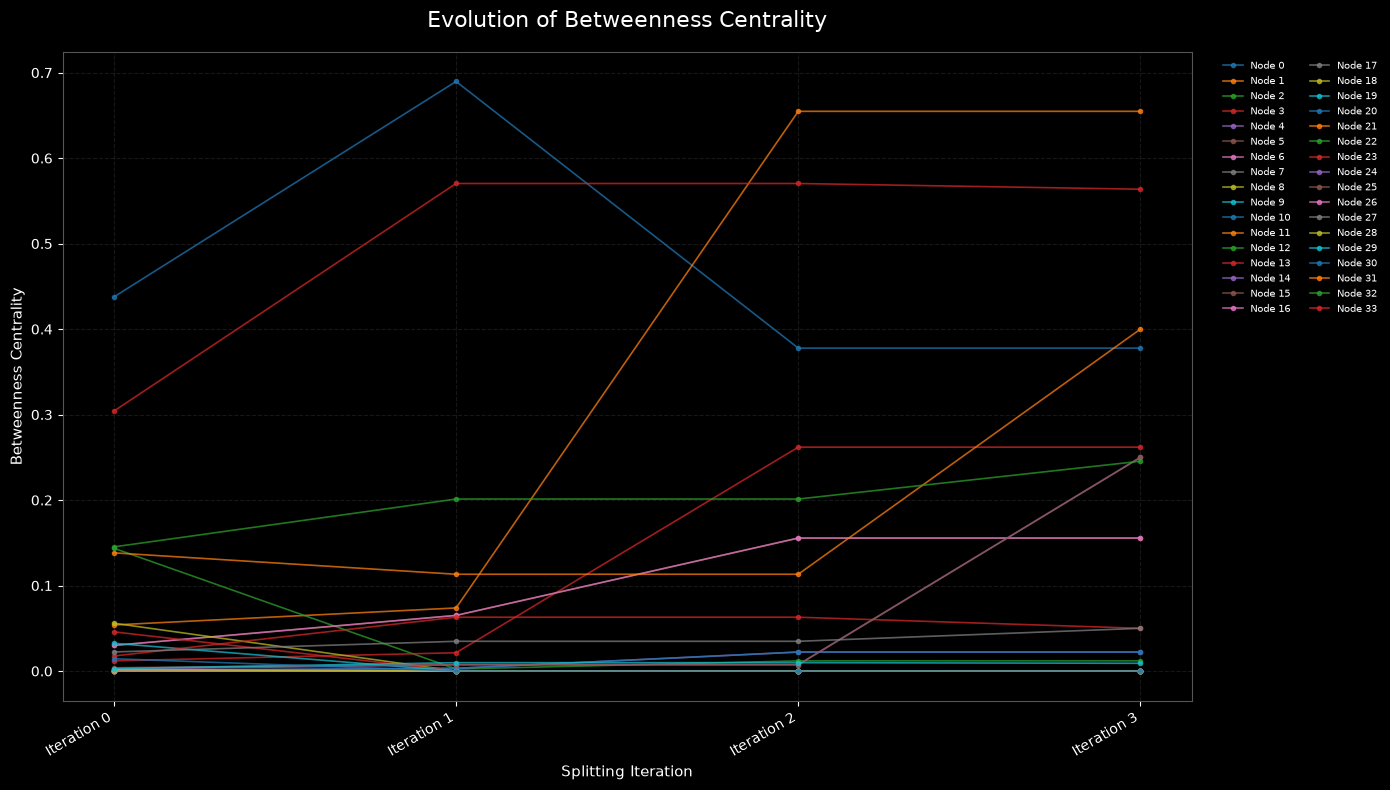

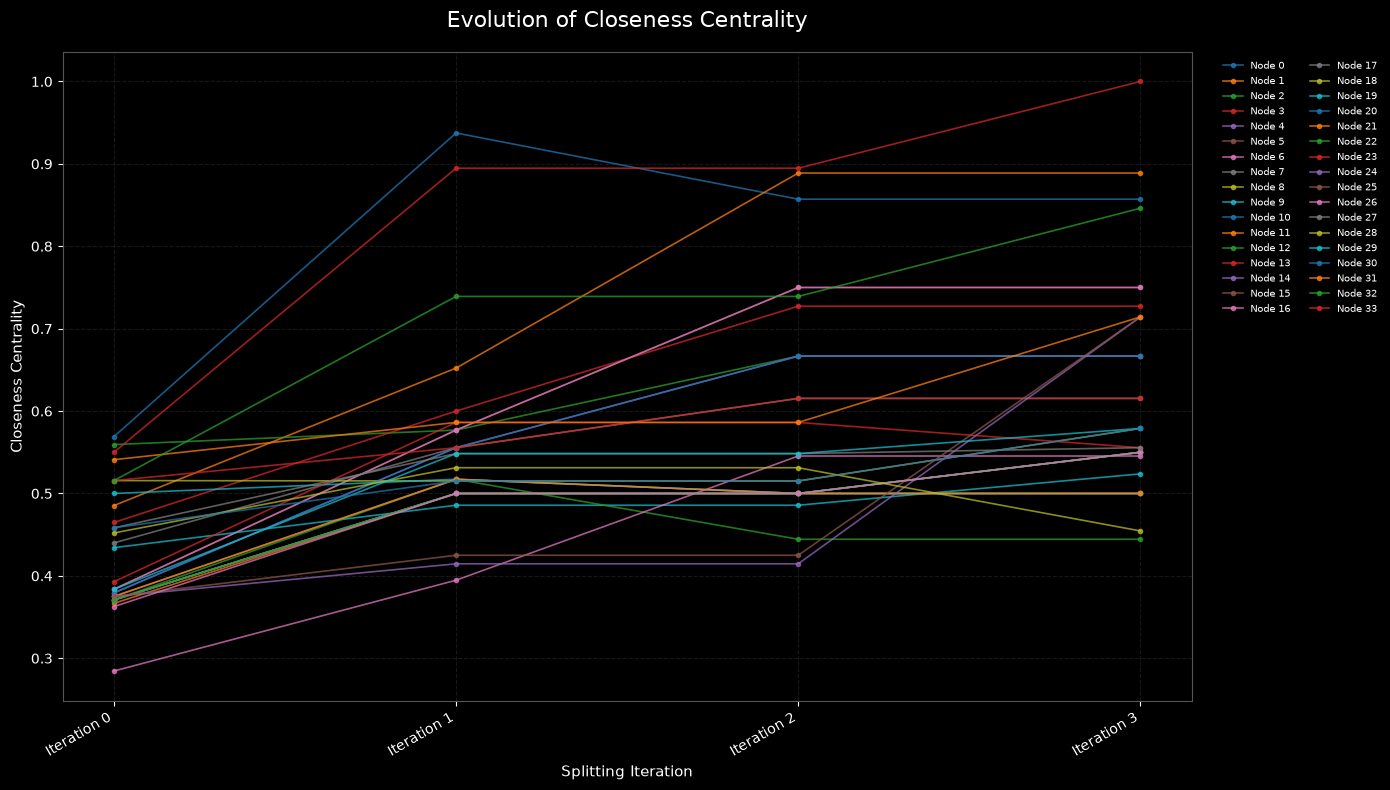

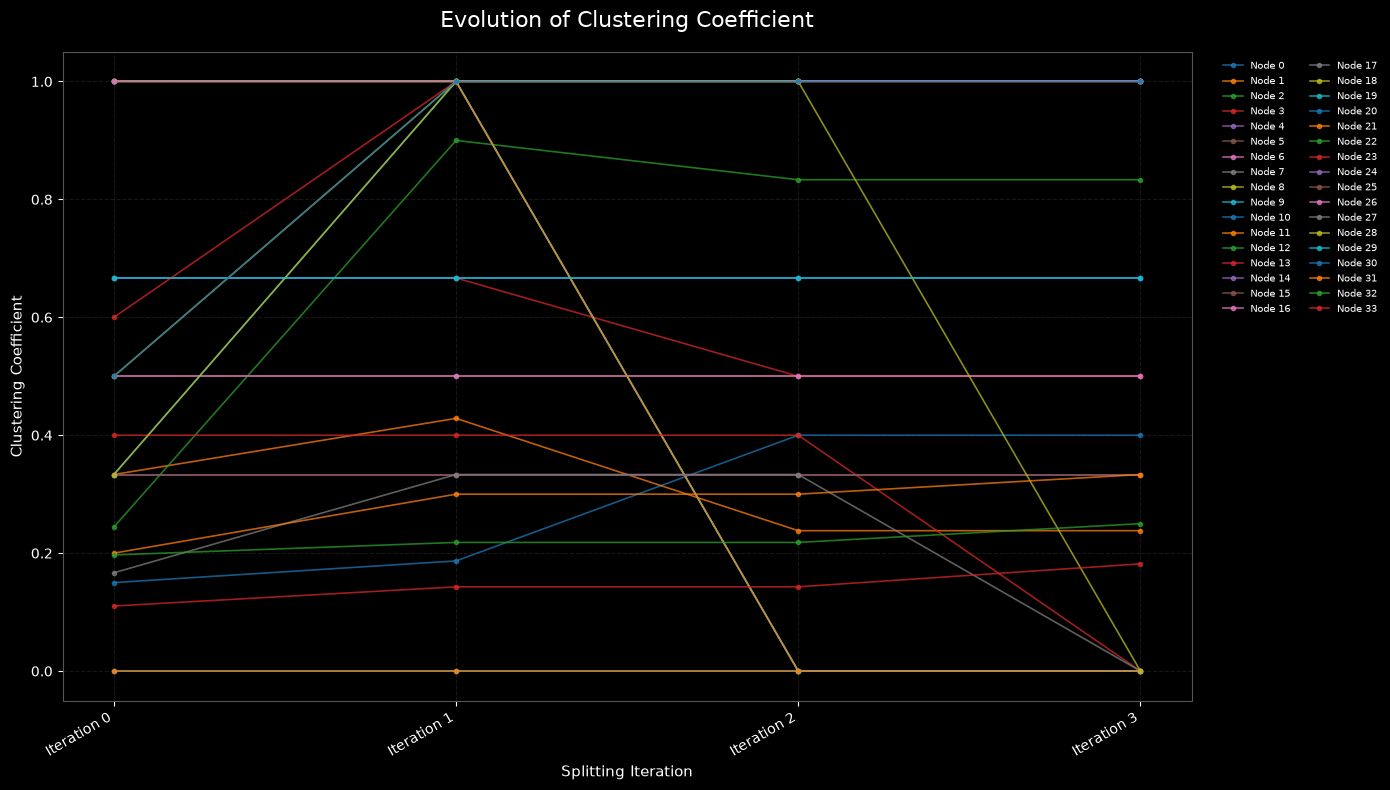

In [223]:

metric_names = [
    "Degree Centrality",
    "Betweenness Centrality",
    "Closeness Centrality",
    "Clustering Coefficient"
]

iteration_labels = [
    f"Iteration {i}" for i in range(len(partition_history))
]

for metric in metric_names:

    fig, ax = plt.subplots(figsize=(14, 8))

    fig.patch.set_facecolor("#000000")
    ax.set_facecolor("#000000")

    history = metric_history[metric]

    # Plot the evolution of each node
    for node in sorted(G.nodes()):

        values = [
            iteration_data[node]
            for iteration_data in history
        ]

        ax.plot(
            range(len(values)),
            values,
            marker="o",
            markersize=3,
            linewidth=1.2,
            alpha=0.75,
            label=f"Node {node}"
        )

    # Style the chart
    ax.set_title(
        f"Evolution of {metric}",
        color="white",
        fontsize=16,
        pad=18
    )

    ax.set_xlabel(
        "Splitting Iteration",
        color="white",
        fontsize=11
    )

    ax.set_ylabel(
        metric,
        color="white",
        fontsize=11
    )

    ax.set_xticks(range(len(iteration_labels)))
    ax.set_xticklabels(
        iteration_labels,
        rotation=30,
        ha="right",
        color="white"
    )

    ax.tick_params(colors="white")

    ax.grid(
        True,
        color="#444444",
        alpha=0.35,
        linestyle="--"
    )

    # Keep all 34 node labels in the legend
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        ncol=2,
        fontsize=7,
        frameon=False,
        labelcolor="white"
    )

    for spine in ax.spines.values():
        spine.set_color("#555555")

    plt.tight_layout()
    plt.show()


In [224]:

print("TOP 5 NODES IN THE FINAL PARTITION\n")

for metric in metric_names:

    final_values = metric_history[metric][-1]

    ranked_nodes = sorted(
        final_values.items(),
        key=lambda item: item[1],
        reverse=True
    )

    print("\n" + metric)

    for node, value in ranked_nodes[:5]:
        print(f"Node {node}: {value:.4f}")

TOP 5 NODES IN THE FINAL PARTITION


Degree Centrality
Node 33: 1.0000
Node 1: 0.8750
Node 0: 0.8333
Node 32: 0.8182
Node 5: 0.6667

Betweenness Centrality
Node 1: 0.6548
Node 33: 0.5636
Node 31: 0.4000
Node 0: 0.3778
Node 3: 0.2619

Closeness Centrality
Node 33: 1.0000
Node 1: 0.8889
Node 0: 0.8571
Node 32: 0.8462
Node 5: 0.7500

Clustering Coefficient
Node 16: 1.0000
Node 7: 1.0000
Node 13: 1.0000
Node 8: 1.0000
Node 14: 1.0000


Discussion and Interpretation

Community Detection Results

The corrected recursive spectral modularity algorithm identified four communities in the Karate Club network, containing 7, 9, 12 and 6 nodes respectively.

The algorithm performed three successful modularity-improving splits. A further proposed split was rejected because its modularity gain was negative. The final partition achieved a modularity score of approximately **0.3934**, indicating a meaningful community structure.

Analysis of Network Metrics

The four network metrics reveal different aspects of node importance within the detected communities.

Degree Centrality: Node 33 achieved the highest final degree centrality, followed by nodes 1, 0, 32 and 5. These nodes have relatively strong connectivity within their respective communities.

Betweenness Centrality: Node 1 had the highest betweenness centrality, followed by nodes 33, 31, 0 and 3. This suggests that these nodes occupy important positions along shortest paths within their communities.

Closeness Centrality: Node 33 achieved the highest closeness centrality, followed by nodes 1, 0, 32 and 5. These nodes can reach other members of their communities relatively efficiently.

Clustering Coefficient: Nodes 16, 7, 13, 8 and 14 achieved a clustering coefficient of 1.0. This means that all the neighbours of each of these nodes are connected to one another within their respective communities.

Effect of Community Structure

As the original network is divided into smaller communities, connections between different communities are excluded when calculating metrics on the induced subgraphs.

Consequently, centrality values change because the local network structure and the number of available connections change. Degree centrality reflects connectivity within each community, while betweenness and closeness centrality capture changes in shortest-path relationships.

The clustering coefficient provides additional information about local cohesion and the interconnectedness of neighbours.

The metric evolution plots demonstrate that node importance depends not only on the number of connections but also on the community structure in which each node is embedded.

Conclusion

This assignment demonstrates how spectral modularity can be used to identify communities in a real-world social network.

The initial recursive implementation revealed a limitation associated with directly using the restricted modularity matrix. A diagonal correction was subsequently introduced to obtain a more reliable spectral splitting procedure.

The corrected algorithm identified four communities and produced a final modularity score of approximately 0.3934. The centrality analysis further demonstrated that different network metrics capture different structural roles within communities.

Overall, the experiment illustrates the relationship between modularity, community detection, network centrality and local network cohesion.

References

1. Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.

2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.

3. NetworkX Developers. *NetworkX Documentation*. https://networkx.org/documentation/stable/

4. NumPy Developers. *NumPy Documentation*. https://numpy.org/doc/